In [1]:

import matplotlib.pyplot as plt
from alpha_beta_complex import (sim_analysis_params_default, run_alpha_beta_complex_simulations,
                                compute_psd, compute_tfr, compute_tfr_mne, alpha_beta_ratio, run_main)
import random
import pandas as pd
import os
import os.path as op
import numpy as np
import pickle

from hnn_core import duecker_ET_model, simulate_dipole

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/alpha_beta'
os.makedirs(pathfig, exist_ok=True)

main_pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/alpha_beta/'
out_pth = op.join(main_pth, 'sim_results')
path_fig = op.join(out_pth, 'figures')
os.makedirs(out_pth, exist_ok=True)
os.makedirs(path_fig, exist_ok=True)

n_procs = 10

import time
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42

In [2]:
params = sim_analysis_params_default()
params['n_procs'] = n_procs
params['prox_seed'] = 544
params['dist_seed'] = 544

In [3]:
t = time.time()
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=1)
elapsed = time.time() - t

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

(0.0, 50.0)

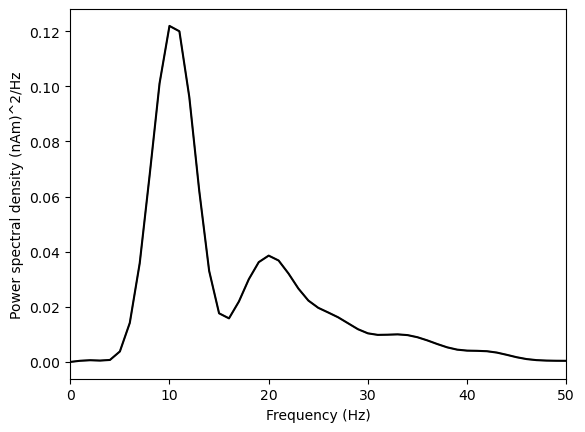

In [4]:
f, psd = compute_psd(params, dpl)
plt.plot(f[0], np.mean(psd, axis=0), color='k')
plt.fill_between(f[0], np.mean(psd, axis=0) - np.std(psd, axis=0), np.mean(psd, axis=0) + np.std(psd, axis=0), alpha=0.3, color='k')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power spectral density (nAm)^2/Hz')
plt.xlim([0, 50])

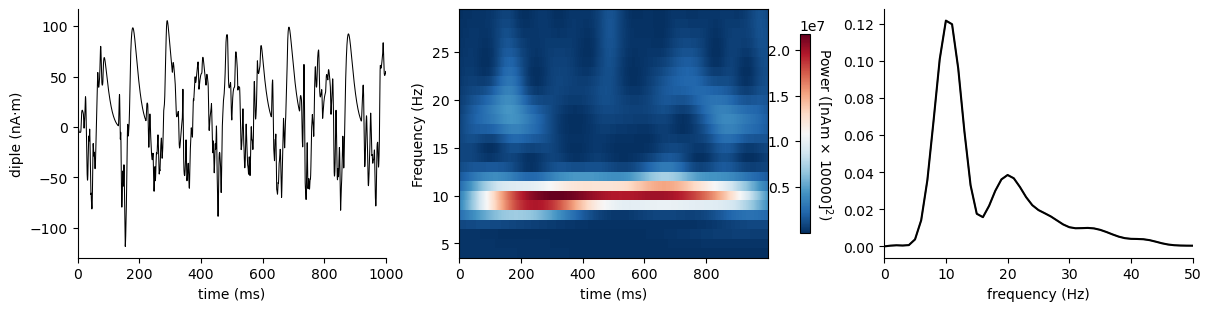

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
ax[0].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=0.75)
ax[0].set_ylabel('diple (nA·m)')
ax[0].set_xlabel('time (ms)')
ax[0].set_xlim([0, 1000])
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
freqs = np.arange(4, 30, 1.)
dpl[0].plot_tfr_morlet(freqs, ax=ax[1], n_cycles=7, show=False, colormap='RdBu_r')
ax[1].set_xlabel('time (ms)')
ax[2].plot(f[0], np.mean(psd, axis=0), color='k')
ax[2].fill_between(f[0], np.mean(psd, axis=0) - np.std(psd, axis=0), np.mean(psd, axis=0) + np.std(psd, axis=0), alpha=0.3, color='k')
ax[2].set_xlim([0, 50])
ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)
ax[2].set_xlabel('frequency (Hz)')

fig.savefig(op.join(pathfig, 'alpha_beta_complex_example.png'), dpi=300)
fig.savefig(op.join(pathfig, 'alpha_beta_complex_example.pdf'))


In [6]:
# from scipy import signal
# frequencies = np.arange(1, 40, 1)  # frequencies
# m = 7                               # number of cycles

# sigma_t = m/(2*np.pi*frequencies)
# A = 1/(sigma_t*np.sqrt(2*np.pi))        # normalization factor

# # create wavelets
# wavelets = []
# for fi, f in enumerate(frequencies):

#     # timevec is different for each frequency
#     timevec = np.arange(0.0, 7.0*sigma_t[fi], 1/dpl.sfreq)
#     # row wise merging (np.r_) -> real and imaginary part of the wavelet are symmetric (without this, we only get half a wavelet)
#     timevec = np.r_[-timevec[::-1], timevec[1:]]
#     oscillation = np.exp(2*1j*np.pi*f*timevec)
#     gaussian_envelope = np.exp(-(timevec**2)/(2*sigma_t[fi]**2))
#     # create wavelet based on formula in Jones 2009
#     wavelets.append(A[fi]*oscillation*gaussian_envelope)

# # # convolve wavelets with signal
# tfr = np.zeros((len(frequencies), len(dpl.data['agg'])))
# for fi, f in enumerate(frequencies):
#     convolved = signal.convolve(dpl.data['agg'], wavelets[fi], mode='full')
#     start = wavelets[fi].size // 2
#     end = len(convolved) - (wavelets[fi].size // 2)
#     # take the middle values
#     tfr[fi, :] = np.abs(convolved[start:end])**2

In [7]:
dpl

In [8]:
frequencies, tfr = compute_tfr(dpl)
freq, times, power, pad_dpl = compute_tfr_mne(dpl)
# idx = (times >= 0) & (times <= 1001)
# power = power[:, idx]


In [9]:
tfr

array([[[6.8063597e+08, 6.8064448e+08, 6.8065306e+08, ...,
         9.4123206e+08, 9.4123155e+08, 9.4123098e+08],
        [9.9200909e+08, 9.9201645e+08, 9.9202387e+08, ...,
         1.1228127e+09, 1.1228015e+09, 1.1227904e+09],
        [1.8420027e+09, 1.8420657e+09, 1.8421285e+09, ...,
         1.2421716e+09, 1.2421142e+09, 1.2420567e+09],
        ...,
        [1.3571350e+10, 1.3588852e+10, 1.3606363e+10, ...,
         7.0626451e+10, 7.0579577e+10, 7.0532661e+10],
        [1.3774783e+10, 1.3793962e+10, 1.3813153e+10, ...,
         6.0441432e+10, 6.0405805e+10, 6.0370129e+10],
        [1.3658112e+10, 1.3678356e+10, 1.3698615e+10, ...,
         5.1613262e+10, 5.1587633e+10, 5.1561955e+10]]],
      shape=(1, 39, 40001), dtype=float32)

In [10]:
tfr.astype(np.float32)

array([[[6.8063597e+08, 6.8064448e+08, 6.8065306e+08, ...,
         9.4123206e+08, 9.4123155e+08, 9.4123098e+08],
        [9.9200909e+08, 9.9201645e+08, 9.9202387e+08, ...,
         1.1228127e+09, 1.1228015e+09, 1.1227904e+09],
        [1.8420027e+09, 1.8420657e+09, 1.8421285e+09, ...,
         1.2421716e+09, 1.2421142e+09, 1.2420567e+09],
        ...,
        [1.3571350e+10, 1.3588852e+10, 1.3606363e+10, ...,
         7.0626451e+10, 7.0579577e+10, 7.0532661e+10],
        [1.3774783e+10, 1.3793962e+10, 1.3813153e+10, ...,
         6.0441432e+10, 6.0405805e+10, 6.0370129e+10],
        [1.3658112e+10, 1.3678356e+10, 1.3698615e+10, ...,
         5.1613262e+10, 5.1587633e+10, 5.1561955e+10]]],
      shape=(1, 39, 40001), dtype=float32)

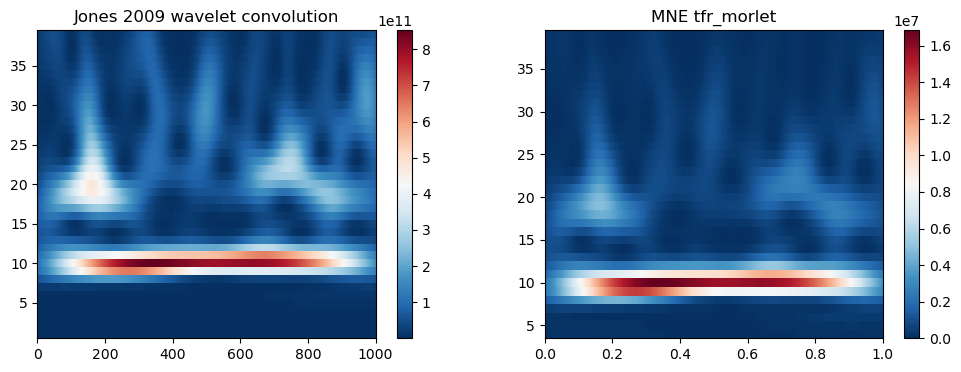

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].pcolormesh(dpl[0].times, frequencies, tfr.mean(axis=0), cmap='RdBu_r')
ax[0].set_title('Jones 2009 wavelet convolution')
plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(times, freq, power.mean(axis=0), cmap='RdBu_r')
ax[1].set_title('MNE tfr_morlet')
ax[1].set_xlim([0, 1])
plt.colorbar(im, ax=ax[1])

fig.savefig(op.join(pathfig, 'tfr_comparison.png'), dpi=300)


In [12]:
ratio, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

In [13]:
df = run_main(n_trials=10, n_procs=10)

MPI will run 10 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading c

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:211: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


RuntimeError: MPI simulation failed. Return code: 1

In [ ]:
df

,trial_index,alpha_beta_ratio,alpha_power,beta_power,prob_overlap,symmetry_index
0,0,"[1.4590108547202882, 2.49411891377381, 3.88973...","[82131163563.34732, 105278904567.14713, 163609...","[56292359510.301895, 42210860110.054405, 42061...",0.454545,"[0.8521337973135609, 0.30959475221766924, -0.6..."
1,1,"[2.6190867947236502, 1.884177150056473, 2.9313...","[124374676840.94188, 156316738989.59058, 20166...","[47487802653.77388, 82962867363.5626, 68798259...",0.454545,"[0.15305262625658744, -0.4808572475858113, 0.0..."
2,2,"[0.44657089194492744, 1.052498540767088, 0.903...","[74828348421.86134, 90770431610.99577, 9330276...","[167562082015.6129, 86242809937.61754, 1032765...",0.454545,"[0.6465384672613291, 0.048960196427453806, -0...."
3,3,"[0.5124634469632072, 1.8796747454077185, 2.028...","[65773165942.834526, 66398335114.5159, 7393739...","[128347038862.18204, 35324374749.79933, 364441...",0.454545,"[0.9080076716575606, -0.14072725913430573, -0...."
4,4,"[3.4186579256553977, 1.879606694793015, 0.8778...","[34065699855.957756, 47156030465.143715, 70790...","[9964641270.573145, 25088243511.676044, 806426...",0.454545,"[0.7786255106372296, 0.15025546325383968, -0.2..."
5,5,"[2.209318251324938, 1.8766341580261467, 2.4961...","[157796764531.57922, 146506231043.46164, 12375...","[71423283828.37004, 78068615780.4767, 49578808...",0.454545,"[0.5762525941129338, -0.16559982353817573, -0...."
6,6,"[0.7793127396565575, 1.122544260208275, 3.6430...","[70096211356.48253, 87185039268.85287, 1301476...","[89946189494.31505, 77667351176.5823, 35724480...",0.454545,"[-0.725318672767866, -0.5756697659107325, 0.40..."
7,7,"[1.0862739511270283, 1.672808643804025, 1.4637...","[132786063853.42674, 134824986554.12071, 93557...","[122239941145.28741, 80597973386.55783, 639146...",0.454545,"[0.6162697944362089, 0.4489385576128416, -0.06..."
8,8,"[2.536987921872241, 4.8792112212636445, 1.4156...","[99967744663.22946, 92741863113.89722, 9359279...","[39404107446.225235, 19007552431.77983, 661127...",0.454545,"[0.7092543112108777, 0.16143457556889224, -0.1..."
9,9,"[3.593421701450705, 1.0557961894136223, 1.9034...","[38779411749.80265, 46321229521.68286, 6351675...","[10791778692.199406, 43873268331.65515, 333696...",0.454545,"[-0.17368231839358403, 0.6663693585604019, -0...."


(array([11., 16., 20., 19., 47., 44., 24., 17., 10.,  7.]),
 array([-0.97545706, -0.77895488, -0.58245271, -0.38595053, -0.18944835,
         0.00705383,  0.203556  ,  0.40005818,  0.59656036,  0.79306253,
         0.98956471]),
 <BarContainer object of 10 artists>)

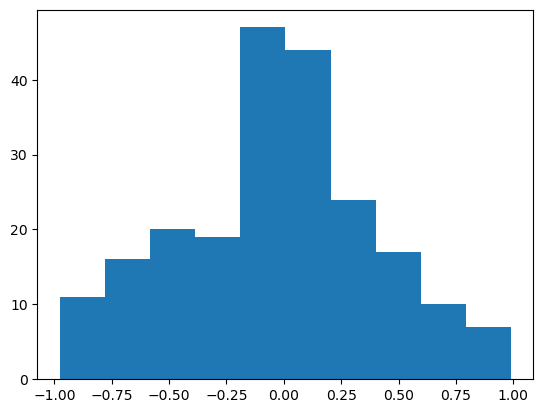

In [ ]:
plt.hist(np.concatenate(df.symmetry_index.values))

(array([20., 41., 22.,  5.,  7.,  2.,  1.,  0.,  1.,  1.]),
 array([0.1299548 , 0.99445391, 1.85895303, 2.72345214, 3.58795125,
        4.45245036, 5.31694948, 6.18144859, 7.0459477 , 7.91044681,
        8.77494593]),
 <BarContainer object of 10 artists>)

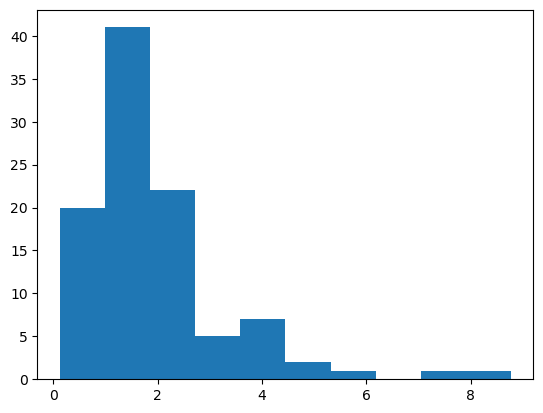

In [ ]:
plt.hist(np.concatenate(df.alpha_beta_ratio.values))

In [ ]:
np.mean(np.concatenate(df.alpha_beta_ratio.values))

np.float64(1.9279871796704924)

In [ ]:
np.median(np.concatenate(df.alpha_beta_ratio.values))

np.float64(1.556727607403261)